In [3]:
# Data manipulation

import pandas as pd
import numpy as np

# Data visualization

import matplotlib.pyplot as pyplot
import seaborn as sns
import pandas as pd
import numpy as np

# Display settings
pd.set_option('display.max_columns', None)
# Data manipulation


# Data visualization

import matplotlib.pyplot as pyplot

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Visualization style
sns.set_style("whitegrid")

print("Libraries imported successfully")

#Visulaiztion style

sns.set_style("whitegrid")

print("Libraries imported sucessfully")


Libraries imported successfully
Libraries imported sucessfully


In [5]:
#Load Dataset
df = pd.read_csv(r"C:\Users\VISHNU\Downloads\Internship\Dataset\Day3\DATA\Netflix_cleaned.csv")

#Display first five rows
print(df.head())

#Dataset shape
print("Row and Columns:", df.shape)

#Columns names
print(df.columns)

#Dataset Information
df.info()

  show_id     type                             title         director  \
0      s1    Movie              Dick Johnson Is Dead  Kirsten Johnson   
1      s3  Tv Show                         Ganglands  Julien Leclercq   
2      s6  Tv Show                     Midnight Mass    Mike Flanagan   
3     s14    Movie  Confessions of an Invisible Girl    Bruno Garotti   
4      s8    Movie                           Sankofa     Haile Gerima   

                                             country date_added  release_year  \
0  ,,,U,,,n,,,i,,,t,,,e,,,d,,,S,,,t,,,a,,,t,,,e,,...  9/25/2021          2020   
1                        ,,,F,,,r,,,a,,,n,,,c,,,e,,,  9/24/2021          2021   
2  ,,,U,,,n,,,i,,,t,,,e,,,d,,,S,,,t,,,a,,,t,,,e,,...  9/24/2021          2021   
3                        ,,,B,,,r,,,a,,,z,,,i,,,l,,,  9/22/2021          2021   
4  ,,,U,,,n,,,i,,,t,,,e,,,d,,,S,,,t,,,a,,,t,,,e,,...  9/24/2021          1993   

  rating  duration                                          listed_in  
0 

In [7]:
#Checking missing values
print(df['country'].isnull().sum())

#Check country values
print(df['country'].head(10))

#check unique countries
print(df['country'].nunique())

0
0    ,,,U,,,n,,,i,,,t,,,e,,,d,,,S,,,t,,,a,,,t,,,e,,...
1                          ,,,F,,,r,,,a,,,n,,,c,,,e,,,
2    ,,,U,,,n,,,i,,,t,,,e,,,d,,,S,,,t,,,a,,,t,,,e,,...
3                          ,,,B,,,r,,,a,,,z,,,i,,,l,,,
4    ,,,U,,,n,,,i,,,t,,,e,,,d,,,S,,,t,,,a,,,t,,,e,,...
5    ,,,U,,,n,,,i,,,t,,,e,,,d,,,K,,,i,,,n,,,g,,,d,,...
6    ,,,U,,,n,,,i,,,t,,,e,,,d,,,S,,,t,,,a,,,t,,,e,,...
7                              ,,,I,,,n,,,d,,,i,,,a,,,
8                      ,,,G,,,e,,,r,,,m,,,a,,,n,,,y,,,
9                              ,,,I,,,n,,,d,,,i,,,a,,,
Name: country, dtype: str
86


In [10]:
#Create a copy
df['country_clean'] = df['country']

#Removal unwanted Commas

df['country_clean'] = (
    df['country_clean']
    .str.replace(r',+', '', regex=True)
    .str.strip()
)

#Covert NotGiven into missing values
df['country_clean'] = df['country_clean'].replace(
    'NotGiven',np.nan
)

#Display cleaned country values

print(df[['country','country_clean']].head(15))

                                              country  country_clean
0   ,,,U,,,n,,,i,,,t,,,e,,,d,,,S,,,t,,,a,,,t,,,e,,...   UnitedStates
1                         ,,,F,,,r,,,a,,,n,,,c,,,e,,,         France
2   ,,,U,,,n,,,i,,,t,,,e,,,d,,,S,,,t,,,a,,,t,,,e,,...   UnitedStates
3                         ,,,B,,,r,,,a,,,z,,,i,,,l,,,         Brazil
4   ,,,U,,,n,,,i,,,t,,,e,,,d,,,S,,,t,,,a,,,t,,,e,,...   UnitedStates
5   ,,,U,,,n,,,i,,,t,,,e,,,d,,,K,,,i,,,n,,,g,,,d,,...  UnitedKingdom
6   ,,,U,,,n,,,i,,,t,,,e,,,d,,,S,,,t,,,a,,,t,,,e,,...   UnitedStates
7                             ,,,I,,,n,,,d,,,i,,,a,,,          India
8                     ,,,G,,,e,,,r,,,m,,,a,,,n,,,y,,,        Germany
9                             ,,,I,,,n,,,d,,,i,,,a,,,          India
10                            ,,,I,,,n,,,d,,,i,,,a,,,          India
11                            ,,,I,,,n,,,d,,,i,,,a,,,          India
12                ,,,P,,,a,,,k,,,i,,,s,,,t,,,a,,,n,,,       Pakistan
13  ,,,U,,,n,,,i,,,t,,,e,,,d,,,S,,

In [15]:
#Count Missing country records

missing_country = df['country_clean'].isnull().sum()

#Caluclate percentage

mising_percentage =(
    missing_country / len(df)
)*100

print("Missing Country Records")
print("Missing Percentage:", round(mising_percentage, 2), "%")

Missing Country Records
Missing Percentage: 3.27 %


In [16]:
 #Remove Missing countries for Analysis

country_df = df.dropna(
    subset=['country_clean']
).copy()

print("Records after cleaning", country_df.shape)

Records after cleaning (8503, 11)


In [17]:
#Count content by country

country_counts = (
    country_df['country_clean']
    .value_counts()
    .reset_index()
)

country_counts.columns =[
    'country',
    'Total_Content'
]
print(country_counts.head(20))

          country  Total_Content
0    UnitedStates           3240
1           India           1057
2   UnitedKingdom            638
3        Pakistan            421
4          Canada            271
5           Japan            259
6      SouthKorea            214
7          France            213
8           Spain            182
9          Mexico            138
10          Egypt            123
11      Australia            114
12         Turkey            112
13        Nigeria            105
14        Germany            104
15          China            100
16         Brazil             88
17         Taiwan             86
18      Indonesia             86
19    Philippines             83


In [18]:
#Sort countries by content count

country_counts = country_counts.sort_values(
    by='Total_Content',
    ascending=False
)

print(country_counts.head(10))

         country  Total_Content
0   UnitedStates           3240
1          India           1057
2  UnitedKingdom            638
3       Pakistan            421
4         Canada            271
5          Japan            259
6     SouthKorea            214
7         France            213
8          Spain            182
9         Mexico            138


In [20]:
#Separate Movies and TV Shows by country
country_type = pd.pivot_table(
    country_df,
    index='country_clean',
    columns='type',
    values='show_id',
    aggfunc='count',
    fill_value=0
)

country_type['Total_Content'] =(
    country_type.sum(axis=1)
)

country_type = country_type.sort_values(
    by='Total_Content',
    ascending=False
)

print(country_type.head(10))

type           Movie  Tv Show  Total_Content
country_clean                               
UnitedStates    2395      845           3240
India            976       81           1057
UnitedKingdom    387      251            638
Pakistan          71      350            421
Canada           187       84            271
Japan             87      172            259
SouthKorea        49      165            214
France           148       65            213
Spain            129       53            182
Mexico            90       48            138


In [21]:
#find the top 10 countries

top_10_countries = country_counts.head(10)

print("Top 10 NETFLIX CONTENT-PRODUCING COUNTRIES")
print(top_10_countries.to_string(index=False))

Top 10 NETFLIX CONTENT-PRODUCING COUNTRIES
      country  Total_Content
 UnitedStates           3240
        India           1057
UnitedKingdom            638
     Pakistan            421
       Canada            271
        Japan            259
   SouthKorea            214
       France            213
        Spain            182
       Mexico            138


In [22]:
#Caluclate Country By Ranking

country_counts['Rank'] =(
    country_counts['Total_Content']
    .rank(method='dense', ascending=False)
    .astype(int)
)

print(country_counts.head(10))

         country  Total_Content  Rank
0   UnitedStates           3240     1
1          India           1057     2
2  UnitedKingdom            638     3
3       Pakistan            421     4
4         Canada            271     5
5          Japan            259     6
6     SouthKorea            214     7
7         France            213     8
8          Spain            182     9
9         Mexico            138    10


In [23]:
#Calculate percentage contribution
total_content = country_counts['Total_Content'].sum()

country_counts['Percentage'] =(
    country_counts['Total_Content'] /
    total_content * 100
)

print(country_counts.head(10))

         country  Total_Content  Rank  Percentage
0   UnitedStates           3240     1   38.104199
1          India           1057     2   12.430907
2  UnitedKingdom            638     3    7.503234
3       Pakistan            421     4    4.951194
4         Canada            271     5    3.187110
5          Japan            259     6    3.045984
6     SouthKorea            214     7    2.516759
7         France            213     8    2.504998
8          Spain            182     9    2.140421
9         Mexico            138    10    1.622957


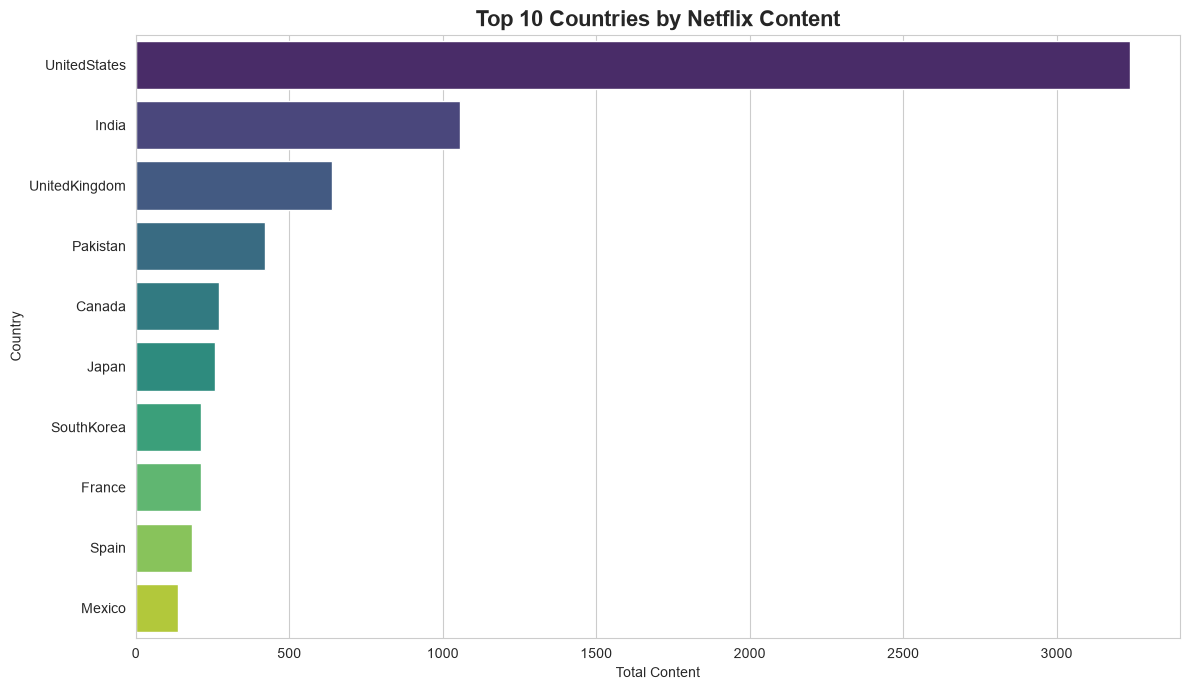

In [25]:
#Top 10 countries by Netflix content

pyplot.figure(figsize=(12,7))

sns.barplot(
    data=top_10_countries,
    x='Total_Content',
    y='country',
    hue='country',
    palette='viridis',
    legend=False
)

pyplot.title(
    'Top 10 Countries by Netflix Content',
    fontsize=16,
    fontweight='bold'
)

pyplot.xlabel('Total Content')
pyplot.ylabel('Country')

pyplot.tight_layout()
pyplot.show()

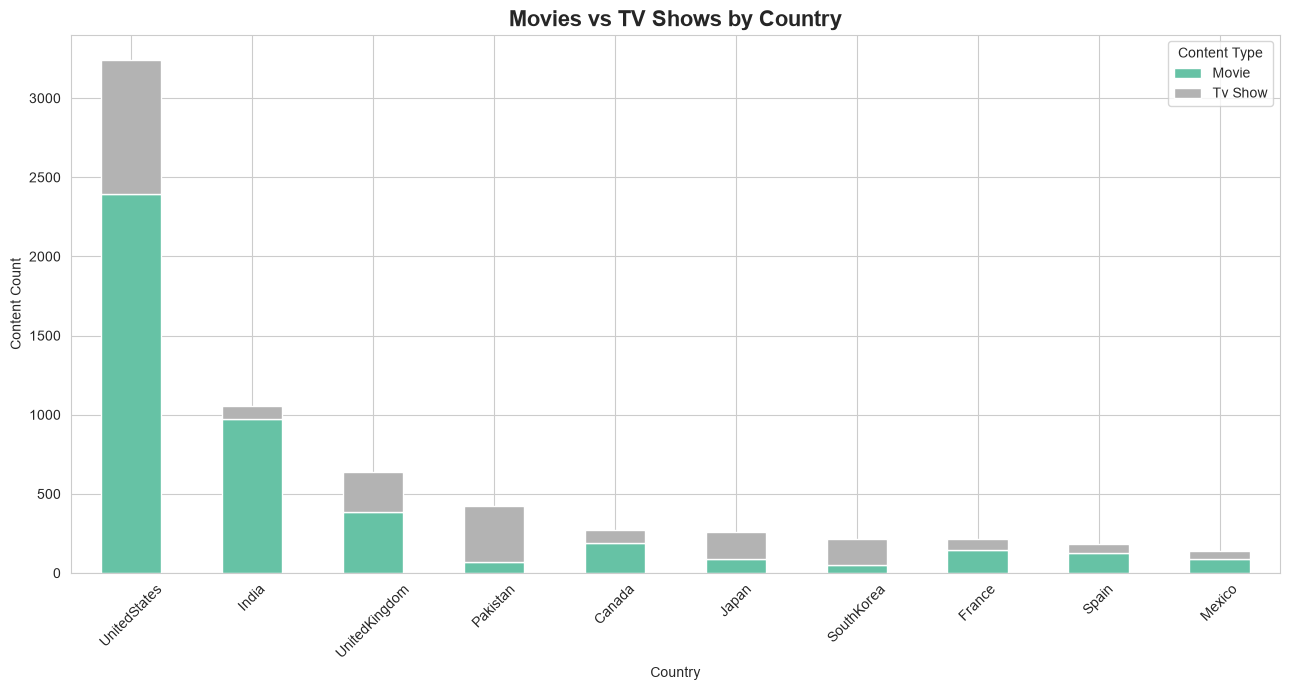

C:\Users\VISHNU\AppData\Local\Temp\ipykernel_4416\1177098660.py:38: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  pyplot.legend(title='Content Type')


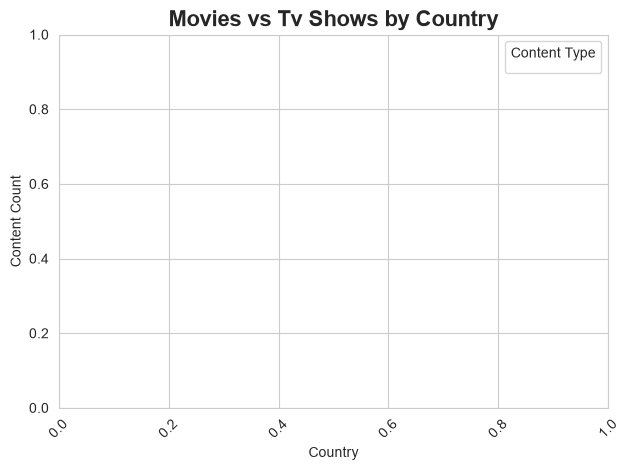

In [28]:
#Country-wise Movie vs TV Show
top_counttries_type = country_type.head(10)

# Country-wise Movie vs TV Show
top_countries_type = country_type.head(10)

top_countries_type[['Movie', 'Tv Show']].plot(
    kind='bar',
    stacked=True,
    figsize=(13, 7),
    colormap='Set2'
)

pyplot.title(
    'Movies vs TV Shows by Country',
    fontsize=16,
    fontweight='bold'
)

pyplot.xlabel('Country')
pyplot.ylabel('Content Count')
pyplot.xticks(rotation=45)
pyplot.legend(title='Content Type')
pyplot.tight_layout()
pyplot.show()


pyplot.title(
    'Movies vs Tv Shows by Country',
    fontsize=16,
    fontweight='bold'
)

pyplot.xlabel('Country')
pyplot.ylabel('Content Count')

pyplot.xticks(rotation=45)
pyplot.legend(title='Content Type')

pyplot.tight_layout()
pyplot.show()

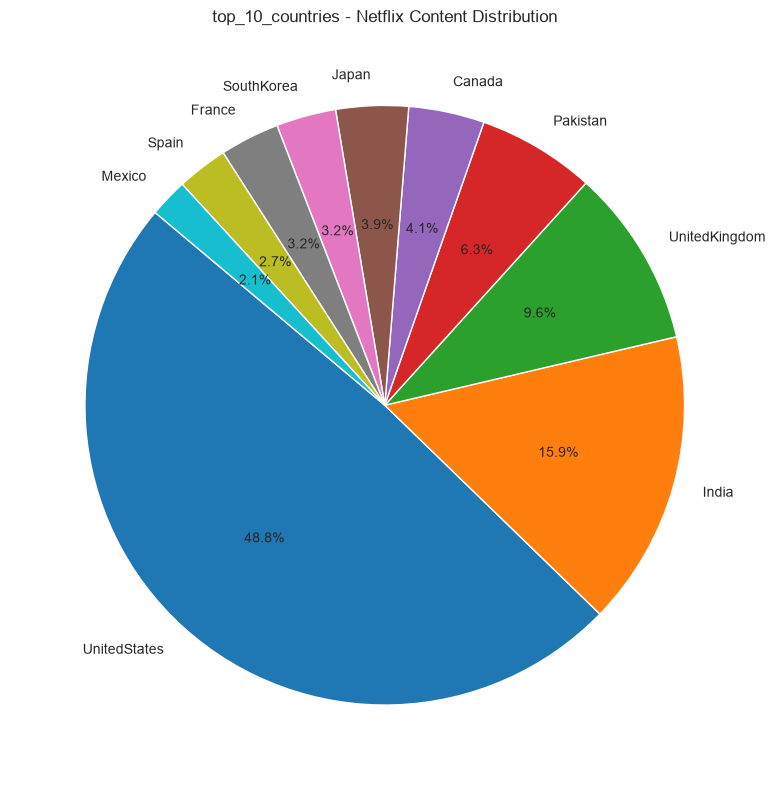

In [30]:
#Top 10 countries percentage contribution
pyplot.figure(figsize=(10,8))

pyplot.pie(
    top_10_countries['Total_Content'],
    labels=top_10_countries['country'],
    autopct='%1.1f%%',
    startangle=140
)

pyplot.title(
    'top_10_countries - Netflix Content Distribution'
)
pyplot.tight_layout()
pyplot.show()

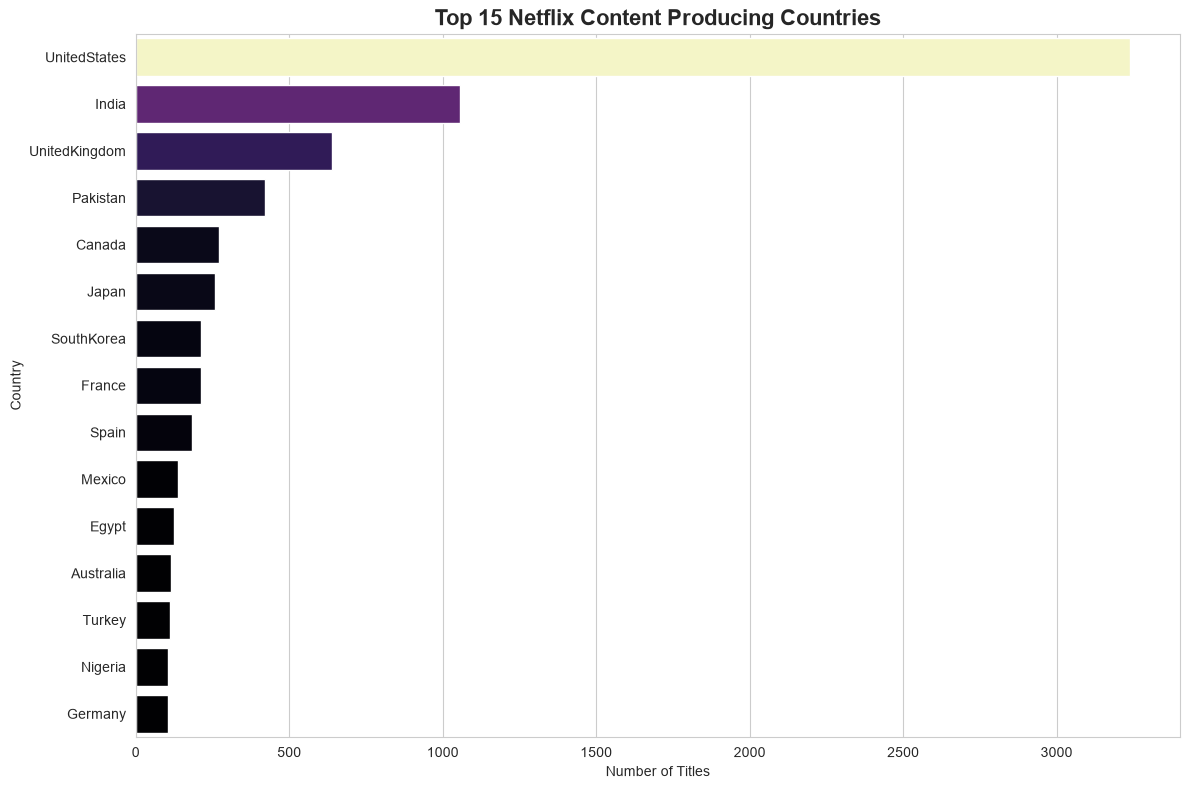

In [32]:
#Top 15 country ranking
top_15 = country_counts.head(15)

pyplot.figure(figsize=(12, 8))

sns.barplot(
    data=top_15,
    x='Total_Content',
    y='country',
    hue='Total_Content',
    palette='magma',
    legend=False
)

pyplot.title(
    'Top 15 Netflix Content Producing Countries',
    fontsize=16,
    fontweight='bold'
)

pyplot.xlabel('Number of Titles')
pyplot.ylabel('Country')

pyplot.tight_layout()
pyplot.show()

In [34]:
#Generate business insights
# Country with maximum content
top_country = country_counts.iloc[0]

# Country with minimum content among top 10
lowest_top10 = country_counts.iloc[9]

# Movie and TV Show leaders
movie_leader = (
    country_type['Movie'].idxmax()
)

tv_leader = (
    country_type['Tv Show'].idxmax()
)

print("========== BUSINESS INSIGHTS ==========")

print(
    f"1. Highest content-producing country: "
    f"{top_country['country']}"
)

print(
    f"2. Total content from this country: "
    f"{top_country['Total_Content']}"
)

print(
    f"3. Movie production leader: {movie_leader}"
)

print(
    f"4. TV Show production leader: {tv_leader}"
)

print(
    f"5. Countries with missing information: "
    f"{missing_country}"
)

print(
    f"6. Top 10 country contribution: "
    f"{round(top_10_countries['Total_Content'].sum() / total_content * 100, 2)}%"
)

========== BUSINESS INSIGHTS ==========
1. Highest content-producing country: UnitedStates
2. Total content from this country: 3240
3. Movie production leader: UnitedStates
4. TV Show production leader: UnitedStates
5. Countries with missing information: 287
6. Top 10 country contribution: 78.01%


In [35]:
#Export your analysis results
# Export cleaned dataset
df.to_csv(
    'Netflix_Country_Cleaned.csv',
    index=False
)

# Export country counts
country_counts.to_csv(
    'Netflix_Country_Ranking.csv',
    index=False
)

# Export movie and TV show analysis
country_type.to_csv(
    'Netflix_Country_Movie_TV_Analysis.csv'
)

print("All analysis files exported successfully!")

All analysis files exported successfully!
